 BBC Sports Classification with Transformer Encoder

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv('/content/drive/My Drive/datasets/bbcsports.csv')
df = df[['text', 'label']]
print(df.shape)
df['label'].value_counts()

(737, 2)


,count
label,
football,265
rugby,147
cricket,124
athletics,101
tennis,100


**Preparing the data**,

In [ ]:
batch_size = 32

train_df, test_df = train_test_split(df, test_size=0.2, random_state=1337, stratify=df['label'])
print(len(train_df), len(test_df))

class_names = sorted(df['label'].unique())
label2id = {c: i for i, c in enumerate(class_names)}
print(label2id)

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df['text'].tolist(), train_df['label'].map(label2id).tolist())).batch(batch_size)
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df['text'].tolist(), test_df['label'].map(label2id).tolist())).batch(batch_size)
text_only_train_ds = train_ds.map(lambda x, y: x)

589 148
{'athletics': 0, 'cricket': 1, 'football': 2, 'rugby': 3, 'tennis': 4}


**Vectorizing the data**

In [ ]:
max_length = 600
max_tokens = 20000
text_vectorization = layers.TextVectorization(
    max_tokens=max_tokens,
    output_mode="int",
    output_sequence_length=max_length,
)
text_vectorization.adapt(text_only_train_ds)

int_train_ds = train_ds.map(
    lambda x, y: (text_vectorization(x), y),
    num_parallel_calls=4)
int_test_ds = test_ds.map(
    lambda x, y: (text_vectorization(x), y),
    num_parallel_calls=4)

**Transformer encoder implemented as a subclassed `Layer`**

In [ ]:
class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim)
        self.dense_proj = keras.Sequential(
            [layers.Dense(dense_dim, activation="relu"),
             layers.Dense(embed_dim),]
        )
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]
        attention_output = self.attention(
            inputs, inputs, attention_mask=mask)
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        return self.layernorm_2(proj_input + proj_output)

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "dense_dim": self.dense_dim,
        })
        return config

**Positional embedding as a subclassed layer**

In [ ]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, input_dim, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_embeddings = layers.Embedding(
            input_dim=input_dim, output_dim=output_dim)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim)
        self.sequence_length = sequence_length
        self.input_dim = input_dim
        self.output_dim = output_dim

    def call(self, inputs):
        length = keras.ops.shape(inputs)[-1]
        positions = keras.ops.arange(0, length, 1)
        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)
        return embedded_tokens + embedded_positions

    def compute_mask(self, inputs, mask=None):
        return keras.ops.not_equal(inputs, 0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "output_dim": self.output_dim,
            "sequence_length": self.sequence_length,
            "input_dim": self.input_dim,
        })
        return config

**Putting it all together: A text-classification Transformer (encoder only, 5 classes so softmax)**

In [ ]:
vocab_size = 20000
sequence_length = 600
embed_dim = 256
num_heads = 2
dense_dim = 32

inputs = keras.Input(shape=(None,), dtype="int64")
x = PositionalEmbedding(sequence_length, vocab_size, embed_dim)(inputs)
x = TransformerEncoder(embed_dim, dense_dim, num_heads)(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(5, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'transformer_encoder' (of type TransformerEncoder) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 256) │  5,273,600 │ input_layer_2[0]… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encoder │ (None, None, 256) │    543,776 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ transformer_enco… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 5)         │      1,285 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,818,661 (22.20 MB)

 Trainable params: 5,818,661 (22.20 MB)

 Non-trainable params: 0 (0.00 B)

**Training on 80% data and evaluating on remaining 20% data**

In [ ]:
model.fit(int_train_ds, epochs=20)
test_acc = model.evaluate(int_test_ds)[1]
print(f"Test acc: {test_acc:.3f}")

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 474ms/step - accuracy: 0.2598 - loss: 4.0149
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.3599 - loss: 2.1795
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.4516 - loss: 1.4959
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.7606 - loss: 0.7120
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8964 - loss: 0.3007
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9643 - loss: 0.1135
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9864 - loss: 0.0361
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9949 - loss: 0.0206
Epoch 9/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9932 - loss: 0.0144
Epoch 10/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9983 - loss: 0.0090
Epoch 11/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 1.0000 - loss: 0.0032
Epoch 12/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accurac

LLM Prompt Design

In [ ]:
labels = ['athletics', 'cricket', 'football', 'rugby', 'tennis']

system_prompt = (
    "You are an expert sports journalist and text classifier. "
    "You will be given a BBC sports news story. "
    "Classify it into exactly one of these five categories: athletics, cricket, football, rugby, tennis. "
    "Reply with ONLY the category name in lowercase, nothing else. Do not use any other category."
)

# few shot examples: (user news, assistant answer)
examples = [
    ("Maria Sharapova came from a set down to beat Alicia Molik 4-6 6-1 6-4 in the final of the Qatar Open.", "tennis"),
    ("Arsenal came from behind to beat Chelsea 2-1 with a late goal from Thierry Henry at Highbury.", "football"),
    ("England bowlers dismissed South Africa for 180 on day two of the second Test at Centurion.", "cricket"),
    ("Wales fly-half scored 15 points as they beat Italy 28-12 in their opening Six Nations match.", "rugby"),
    ("Kelly Holmes won the 800m gold in a season-best time on the final night of the athletics meeting.", "athletics"),
]

def build_messages(news):
    messages = [{"role": "system", "content": system_prompt}]
    for ex_news, ex_label in examples:
        messages.append({"role": "user", "content": f"News: {ex_news}\nCategory:"})
        messages.append({"role": "assistant", "content": ex_label})
    messages.append({"role": "user", "content": f"News: {news[:1500]}\nCategory:"})
    return messages

import json
print(json.dumps(build_messages("Federer wins title in Rotterdam"), indent=2)[:1500])

[
  {
    "role": "system",
    "content": "You are an expert sports journalist and text classifier. You will be given a BBC sports news story. Classify it into exactly one of these five categories: athletics, cricket, football, rugby, tennis. Reply with ONLY the category name in lowercase, nothing else. Do not use any other category."
  },
  {
    "role": "user",
    "content": "News: Maria Sharapova came from a set down to beat Alicia Molik 4-6 6-1 6-4 in the final of the Qatar Open.\nCategory:"
  },
  {
    "role": "assistant",
    "content": "tennis"
  },
  {
    "role": "user",
    "content": "News: Arsenal came from behind to beat Chelsea 2-1 with a late goal from Thierry Henry at Highbury.\nCategory:"
  },
  {
    "role": "assistant",
    "content": "football"
  },
  {
    "role": "user",
    "content": "News: England bowlers dismissed South Africa for 180 on day two of the second Test at Centurion.\nCategory:"
  },
  {
    "role": "assistant",
    "content": "cricket"
  },
  {


Choosing five Models

All the LLMs are called through **OpenRouter** (one API key, one interface for many LLMs), so same code works for every LLM

| LLM | Company | Open source? |
|---|---|---|
| gpt-4o-mini | OpenAI | No (closed) |
| llama-3.1-8b-instruct | Meta | Yes (open weights) |
| deepseek-chat (V3) | DeepSeek | Yes (open weights) |
| gemini-2.5-flash-lite | Google | No (closed) |
| mistral-nemo | Mistral AI | Yes (open, Apache 2.0) |

In [ ]:
!pip install openai

In [ ]:
from google.colab import userdata
key = userdata.get('openrouter')

In [ ]:
import os
os.environ["OPENROUTER_API_KEY"] = key
from openai import OpenAI
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=key,
)

In [ ]:
llm_models = {
    "GPT-4o-mini (OpenAI)": "openai/gpt-4o-mini",
    "Llama-3.1-8B (Meta)": "meta-llama/llama-3.1-8b-instruct",
    "DeepSeek-V3 (DeepSeek)": "deepseek/deepseek-chat",
    "Gemini-2.5-Flash-Lite (Google)": "google/gemini-2.5-flash-lite",
    "Mistral-NeMo (Mistral AI)": "mistralai/mistral-nemo",
}

available_ids = {m.id for m in client.models.list().data}
for name, model_id in llm_models.items():
    print(name, "->", model_id, "| available:", model_id in available_ids)

GPT-4o-mini (OpenAI) -> openai/gpt-4o-mini | available: True
Llama-3.1-8B (Meta) -> meta-llama/llama-3.1-8b-instruct | available: True
DeepSeek-V3 (DeepSeek) -> deepseek/deepseek-chat | available: True
Gemini-2.5-Flash-Lite (Google) -> google/gemini-2.5-flash-lite | available: True
Mistral-NeMo (Mistral AI) -> mistralai/mistral-nemo | available: True


function to send one news text to one LLM

In [ ]:
import time

def chat_with_llm(model_id, news):
    """Send a news text to the given LLM and return its raw reply."""
    for attempt in range(3):
        try:
            response = client.chat.completions.create(
                model=model_id,
                messages=build_messages(news),
                temperature=0,
                max_tokens=10,
            )
            return response.choices[0].message.content or ""
        except Exception as e:
            time.sleep(2)
    return ""

def extract_label(reply):
    """Find which of the five categories the LLM replied with."""
    reply = reply.lower()
    found = [(reply.find(l), l) for l in labels if l in reply]
    if len(found) == 0:
        return "unknown"
    return min(found)[1]

# quick test
print(chat_with_llm("openai/gpt-4o-mini", "Federer wins title in Rotterdam"))

tennis


Select 200 instances (40 from each class)

In [ ]:
sample_df = pd.concat(
    [df[df['label'] == l].sample(40, random_state=1337) for l in labels]
).reset_index(drop=True)

print(len(sample_df))
sample_df['label'].value_counts()

200


,count
label,
athletics,40
cricket,40
football,40
rugby,40
tennis,40


##Part 5: Classification with all five LLMs

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

original = sample_df['label'].tolist()
news_list = sample_df['text'].tolist()

all_results = {}   # llm name -> list of predicted labels

for llm_name, model_id in llm_models.items():
    print("Running:", llm_name)
    with ThreadPoolExecutor(max_workers=8) as executor:
        replies = list(tqdm(executor.map(lambda n: chat_with_llm(model_id, n), news_list), total=len(news_list)))
    all_results[llm_name] = [extract_label(r) for r in replies]

Running: GPT-4o-mini (OpenAI)


  0%|          | 0/200 [00:00<?, ?it/s]

Running: Llama-3.1-8B (Meta)


  0%|          | 0/200 [00:00<?, ?it/s]

Running: DeepSeek-V3 (DeepSeek)


  0%|          | 0/200 [00:00<?, ?it/s]

Running: Gemini-2.5-Flash-Lite (Google)


  0%|          | 0/200 [00:00<?, ?it/s]

Running: Mistral-NeMo (Mistral AI)


  0%|          | 0/200 [00:00<?, ?it/s]

accuracy of every LLM

In [ ]:
accuracy = {}
for llm_name, result in all_results.items():
    count = 0
    for i in range(len(original)):
        if original[i] == result[i]:
            count = count + 1
    accuracy[llm_name] = (count / len(original)) * 100
    unknown = result.count("unknown")
    print(f"{llm_name}: correct = {count}/{len(original)}, Accuracy Percentage: {accuracy[llm_name]:.2f}, unknown replies = {unknown}")

GPT-4o-mini (OpenAI): correct = 200/200, Accuracy Percentage: 100.00, unknown replies = 0
Llama-3.1-8B (Meta): correct = 200/200, Accuracy Percentage: 100.00, unknown replies = 0
DeepSeek-V3 (DeepSeek): correct = 200/200, Accuracy Percentage: 100.00, unknown replies = 0
Gemini-2.5-Flash-Lite (Google): correct = 200/200, Accuracy Percentage: 100.00, unknown replies = 0
Mistral-NeMo (Mistral AI): correct = 198/200, Accuracy Percentage: 99.00, unknown replies = 1


,LLM,Accuracy %
0,GPT-4o-mini (OpenAI),100.0
1,Llama-3.1-8B (Meta),100.0
2,DeepSeek-V3 (DeepSeek),100.0
3,Gemini-2.5-Flash-Lite (Google),100.0
4,Mistral-NeMo (Mistral AI),99.0


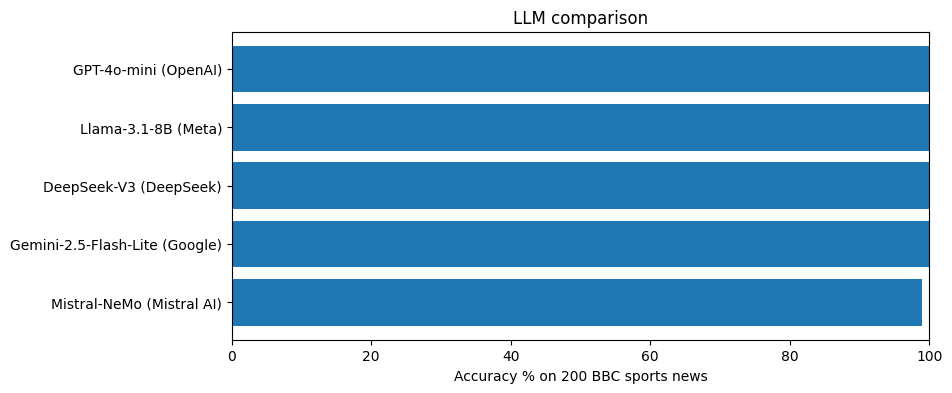

In [ ]:
import matplotlib.pyplot as plt

results_df = pd.DataFrame({"LLM": list(accuracy.keys()), "Accuracy %": list(accuracy.values())})
results_df = results_df.sort_values("Accuracy %", ascending=False).reset_index(drop=True)
display(results_df)

plt.figure(figsize=(9, 4))
plt.barh(results_df["LLM"][::-1], results_df["Accuracy %"][::-1])
plt.xlabel("Accuracy % on 200 BBC sports news")
plt.xlim(0, 100)
plt.title("LLM comparison")
plt.show()

per class accuracy of every LLM (which class is difficult?)

In [ ]:
per_class = {}
for llm_name, result in all_results.items():
    per_class[llm_name] = {}
    for l in labels:
        idx = [i for i in range(len(original)) if original[i] == l]
        per_class[llm_name][l] = sum(result[i] == l for i in idx) / len(idx) * 100

pd.DataFrame(per_class).round(1)

,GPT-4o-mini (OpenAI),Llama-3.1-8B (Meta),DeepSeek-V3 (DeepSeek),Gemini-2.5-Flash-Lite (Google),Mistral-NeMo (Mistral AI)
athletics,100.0,100.0,100.0,100.0,95.0
cricket,100.0,100.0,100.0,100.0,100.0
football,100.0,100.0,100.0,100.0,100.0
rugby,100.0,100.0,100.0,100.0,100.0
tennis,100.0,100.0,100.0,100.0,100.0


comparison with Transformer Encoder (Part 1)

In [ ]:
print(f"Transformer Encoder only (trained on 80%, tested on 20% = {len(test_df)} instances): {test_acc*100:.2f}%")
for llm_name in results_df["LLM"]:
    print(f"{llm_name} (zero training, 200 instances): {accuracy[llm_name]:.2f}%")

Transformer Encoder only (trained on 80%, tested on 20% = 148 instances): 98.65%
GPT-4o-mini (OpenAI) (zero training, 200 instances): 100.00%
Llama-3.1-8B (Meta) (zero training, 200 instances): 100.00%
DeepSeek-V3 (DeepSeek) (zero training, 200 instances): 100.00%
Gemini-2.5-Flash-Lite (Google) (zero training, 200 instances): 100.00%
Mistral-NeMo (Mistral AI) (zero training, 200 instances): 99.00%


##Conclusion

In [ ]:
best_llm = results_df["LLM"][0]
worst_llm = results_df["LLM"][len(results_df) - 1]
print(f"Best performing LLM: {best_llm} with {accuracy[best_llm]:.2f}% accuracy")
print(f"Lowest performing LLM: {worst_llm} with {accuracy[worst_llm]:.2f}% accuracy")
print(f"Transformer Encoder trained on 80% data: {test_acc*100:.2f}%")

Best performing LLM: GPT-4o-mini (OpenAI) with 100.00% accuracy
Lowest performing LLM: Mistral-NeMo (Mistral AI) with 99.00% accuracy
Transformer Encoder trained on 80% data: 98.65%


**Conclusion**

Five LLMs (GPT-4o-mini, Llama 3.1 8B, DeepSeek V3, Gemini 2.5 Flash Lite and Mistral NeMo) were tested on 200 BBC sports news (40 per class) using a system prompt with few-shot user/assistant examples. GPT-4o-mini, Llama 3.1 8B, DeepSeek V3 and Gemini 2.5 Flash Lite all got 100% accuracy, while Mistral NeMo got 99%, its only mistakes were on Balco doping case news, which do not mention any sport. The Transformer Encoder trained on 80% data got 98.65% on the remaining 20%. Since four LLMs tie at 100%, the best choice is Llama 3.1 8B, because it is open source, the smallest of the four and needed no training.

**Lessons learnt**

1. A clear prompt (fixed labels, "reply only with the category" and a few assistant examples) gives clean one-word output that is easy to evaluate.
2. LLMs need no training data, but every prediction costs an API call, while the trained Transformer Encoder runs locally for free and is almost as accurate on this easy task.
3. 100% accuracy shows the task is easy and the test cannot separate good models, so a harder dataset is needed to compare LLMs fairly.
4. Small open-source models can match big closed models on simple tasks, so the model should be chosen by task difficulty, cost and privacy.